# Sharp Equilibrium

DESC is a 3D MHD equilibrium and optimization code suite, which solves the ideal MHD equilibrium equations to find stellarator equilibria. This tutorial is the sharp-boundary counterpart of DESC's [Basic Equilibrium](https://desc-docs.readthedocs.io/en/latest/notebooks/tutorials/basic_equilibrium.html) tutorial: the last closed flux surface is a separatrix, whose cross-sections have sharp corners on the X-lines.

Like a standard DESC equilibrium, a sharp equilibrium (a `RidgeEquilibrium`) requires 4 main inputs to define the equilibrium problem: (1) pressure profile, (2) rotational transform profile (a toroidal current profile is not supported), (3) LCFS boundary shape (now with sharp corners), and (4) total toroidal magnetic flux enclosed. The boundary adds three numbers of its own: the number of corners $m_b$, their toroidal winding $n_b$, and the exponent $\gamma$ of the ridge function. The X-lines must be field lines, so the rotational transform on the boundary is fixed to that of the corners, 
$$\iota_b\equiv\iota(1)=N_\textrm{fp}n_b/m_b.$$

## Creating a Sharp Equilibrium from scratch

We construct and solve a `RidgeEquilibrium` object.

In [1]:
import sys
import os

sys.path.insert(0, os.path.abspath("."))
sys.path.append(os.path.abspath("../../../"))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

from desc.equilibrium import RidgeEquilibrium
from desc.geometry import FourierRZToroidalRidgeSurface
from desc.plotting import plot_comparison
from desc.profiles import PowerSeriesProfile

### The boundary with sharp corners

The boundary is represented by a double Fourier "ridge" series for R and Z in terms of a poloidal angle $\theta$ and the geometric toroidal angle $\zeta$. The position components are
$$
\begin{align}
    R^b(\theta,\zeta) &= A_R(\theta,\zeta) + \mathrm{Re}\,Q_\gamma(\alpha_b)\, B_{1,R}(\theta,\zeta) + \mathrm{Im}\,Q_\gamma(\alpha_b)\, B_{2,R}(\theta,\zeta)\\
    Z^b(\theta,\zeta) &= A_Z(\theta,\zeta) + \mathrm{Re}\,Q_\gamma(\alpha_b)\, B_{1,Z}(\theta,\zeta) + \mathrm{Im}\,Q_\gamma(\alpha_b)\, B_{2,Z}(\theta,\zeta),
\end{align}
$$
where each block $A$, $B_1$, and $B_2$ are represented with a Fourier-Zernike series such that $\sum^M \sum^N X_{mn} \mathcal{G}^{m}_{n}(\theta,\zeta)$ and

$$
   \mathcal{G}^{m}_{n}(\theta,\zeta) = \begin{cases}
   \cos(|m|\theta)\cos(|n|N_{FP}\zeta) &\text{for }m\ge0, n\ge0 \\
   \cos(|m|\theta)\sin(|n|N_{FP}\zeta) &\text{for }m\ge0, n<0 \\
   \sin(|m|\theta)\cos(|n|N_{FP}\zeta) &\text{for }m<0, n\ge0 \\
   \sin(|m|\theta)\sin(|n|N_{FP}\zeta) &\text{for }m<0, n<0.
   \end{cases}
$$

The resolution of $A$ is `M`, `N`, and that of the sharp blocks is `M_b`, `N_b`. We also make the definitions of a helical label 
$$\alpha_b \equiv \theta - \iota_b \zeta,$$
that is constant for an X-line, and $Q_\gamma$ is the ridge function
$$
\begin{align}
    Q_\gamma(\alpha_b) \equiv \frac{|P|}{m_b} e^{i\gamma \arg P}\\\qquad P = 1 - e^{i m_b \alpha_b}.
    \end{align}
$$

The function $Q_\gamma$ is what introduces the corner, vanishing on the ridges $\alpha_b = 2\pi k / m_b$ and about it mapping an angle of $\pi$ to an angle of $\gamma\pi$. We also enforce that $\partial_\theta A=\partial_\rho A=0$, referred to as the "flatness condition" to ensure that the Jacobian has a single-directional limit at each corner. 

### The rotating lemon fit

As an example, we try to recreate the "rotating lemon" from *Stellarator divertor design by optimising coils for surfaces with sharp corners* by Todd Elder.

#### Rotating lemon math

This subsection describes the boundary of the rotating lemon itself as laid out in the paper. Feel free to skip it unless you would like to use it to build intuition. 

The lemon is described by two arcs $j=1$ and $j=2$ along each side, 
$$
    \mathbf{r}_j = \mathbf{r}_{0j} - a\cos\left(\vartheta + \frac{n_{fp}\phi}{2} + \alpha_j\right)\hat{\mathbf{e}}_R - a\sin\left(\vartheta + \frac{n_{fp}\phi}{2} + \alpha_j\right)\hat{\mathbf{e}}_z,
$$
where there exist the parameters $\alpha_1 = 0$ and $\alpha_2 = \pi$ along each arc. They use $R_0 = 1$ m, $d = 0.2$ m, $a = 0.3$ m and $N_{fp} = 4$. In a field period the lemon turns by $\pi$, so its $m_b = 2$ corners wind with $|\iota_b| = 2$. We can now convert from the lemon $(\vartheta,\phi)$ system to our helical $(\alpha_b,\zeta)$ system. The arcs meet at $\vartheta = \pm\vartheta_c$ with $\cos\vartheta_c = d/a$, so to ensure that the two corners are at $\alpha_b=0$ and $\pi$, respectively, we write that $\alpha_b=\pi(1-\vartheta/\vartheta_c)/2+(j-1)\pi$. To ensure stellarator symmetry about the midplane, we label the toroidal angle with $\zeta = \phi - \pi/4$. 

#### The fit itself

In [2]:
R0, d, a, n_fp = 1.0, 0.2, 0.3, 4   # the lemon of Elder et al.
m_b, n_b = 2, -1                    # 2 corners, winding with iota_b = n_fp n_b / m_b = -2
iota_b = n_fp * n_b / m_b
theta_c = np.arccos(d / a)          # where the two arcs meet
corner_angle = np.pi - np.arccos((a**2 - 2 * d**2) / a**2)
gamma = corner_angle / np.pi        # the ridge function makes corners of angle gamma pi
print(f"corner angle = {np.degrees(corner_angle):.1f} deg, gamma = {gamma:.4f}")


def lemon(alpha_b, zeta):
    """R and Z of the rotating lemon (Elder et al., eqs. 2.2-2.3) at the corner angle alpha_b and zeta = phi - pi/4."""
    beta = n_fp * (zeta + np.pi / 4) / 2
    alpha_b = np.mod(alpha_b, 2 * np.pi)
    arc1 = alpha_b < np.pi  # arc j = 1 from the corner alpha_b = 0 to alpha_b = pi, then arc j = 2
    vartheta = theta_c * (1 - 2 * np.mod(alpha_b, np.pi) / np.pi)
    alpha_j = np.where(arc1, 0, np.pi)
    R = R0 + d * np.cos(beta + alpha_j) - a * np.cos(vartheta + beta + alpha_j)
    Z = d * np.sin(beta + alpha_j) - a * np.sin(vartheta + beta + alpha_j)
    return R, Z

corner angle = 96.4 deg, gamma = 0.5354


If you already have points on the boundary, you can fit a `FourierRZToroidalRidgeSurface` to them with `FourierRZToroidalRidgeSurface.from_values`. The points are given in cylindrical coordinates $(R, \phi, Z)$ with their poloidal angle $\theta = \alpha_b + \iota_b\zeta$. We fit the lemon at the lowest resolution, $M = N = M_b = N_b = 1$. The fit is within about a millimetre of the lemon, whose minor radius is about 0.15 m, so we will use it as our boundary.

In [3]:
## points on the lemon: 128 per cross-section on 32 planes of a field period
alpha_fit, zeta_fit = np.meshgrid(2 * np.pi * np.arange(128) / 128, 2 * np.pi / n_fp * np.arange(32) / 32, indexing="ij")
alpha_fit, zeta_fit = alpha_fit.ravel(), zeta_fit.ravel()
R_fit, Z_fit = lemon(alpha_fit, zeta_fit)
coords = np.column_stack([R_fit, zeta_fit, Z_fit])
theta_fit = np.mod(alpha_fit + iota_b * zeta_fit, 2 * np.pi)

## finer points to measure the error, off the fitted ones
alpha_test, zeta_test = np.meshgrid(np.linspace(0, 2 * np.pi, 1000, endpoint=False) + 1e-3,
                                     np.linspace(0, 2 * np.pi / n_fp, 17), indexing="ij")
alpha_test, zeta_test = alpha_test.ravel(), zeta_test.ravel()
R_test, Z_test = lemon(alpha_test, zeta_test)
theta_test = np.mod(alpha_test + iota_b * zeta_test, 2 * np.pi)


def fit_error(surf):
    """RMS and maximum distance (m) of the surface from the lemon, at the same labels."""
    from desc.grid import Grid

    nodes = np.column_stack([np.ones_like(theta_test), theta_test, zeta_test])
    data = surf.compute(["R", "Z"], grid=Grid(nodes, sort=False))
    dist = np.hypot(data["R"] - R_test, data["Z"] - Z_test)
    return np.sqrt(np.mean(dist**2)), np.max(dist)


surf1 = FourierRZToroidalRidgeSurface.from_values(
    coords, theta_fit, M=1, N=1, M_b=1, N_b=1, NFP=n_fp, m_b=m_b, n_b=n_b, gamma=gamma, sym=True
)
rms, err_max = fit_error(surf1)
print(f"fitted lemon: RMS error {rms:.2e} m, max error {err_max:.2e} m")

fitted lemon: RMS error 6.35e-04 m, max error 1.16e-03 m


An alternative method is to start from scratch and specify the coefficients manually. In order to best understand the boundary behavior, we use the helical label $\alpha_b=\theta-\iota_b\zeta$ as this is constant along an X-line. Using the fitted coefficients from above, we can write that the lemon is

$$
\begin{align}
    (R^b - R_0) + iZ^b = e^{2i\zeta}\Big[\, &0.2234\cos\alpha_b 
    - \mathrm{Re}\,Q_\gamma(\alpha_b)\left(0.1276\, e^{i\alpha_b} + 0.0283\, e^{-i\alpha_b}\right) 
    + i\,\mathrm{Im}\,Q_\gamma(\alpha_b)\left(0.1589\, e^{i\alpha_b} - 0.0156\, e^{-i\alpha_b}\right)\Big].
\end{align}
$$

Note how the lemon cross-section is built by the term inside brackets, and there is a rigid rotation applied as $e^{2i\zeta}$. Using the definition of $\alpha_b$, this reduces into a more DESC-ready form as

$$
\begin{align}
    (R^b - R_0) + iZ^b = \; &0.1117\left(e^{i(\theta + N_{FP}\zeta)} + e^{-i\theta}\right) 
    - \mathrm{Re}\,Q_\gamma\left(0.1276\, e^{i(\theta + N_{FP}\zeta)} + 0.0283\, e^{-i\theta}\right) 
    + i\,\mathrm{Im}\,Q_\gamma\left(0.1589\, e^{i(\theta + N_{FP}\zeta)} - 0.0156\, e^{-i\theta}\right).
\end{align}
$$


DESC's coordinates are right handed, with $\theta$ increasing clockwise in the $(R, Z)$ plane, so the corners sit at $\theta = -2\zeta$: $\iota_b = -2$ and $n_b = -1$. DESC's stellarator-symmetric ridge basis puts the corners at $\alpha_b = 0, \pi$, which on $\zeta = 0$ is the midplane, so we label the toroidal angle with $\zeta = \phi - \pi/4$. Then our $\zeta = 0$ is the paper's plane $\phi = 0.25\pi$ (their figure 2), where the lemon lies flat with its corners on the midplane.

In [4]:
c, b1, b1_, b2, b2_ = 0.1117, 0.1276, 0.0283, 0.1589, 0.0156
surf2 = FourierRZToroidalRidgeSurface(
    R_lmn=[R0, c, c, -c, -b1_, -b1, b1, -b2_, -b2, -b2],
    modes_R=[
        (0, 0, 0),
        (1, 0, 0),
        (1, 1, 0),
        (-1, -1, 0),
        (1, 0, 1),
        (1, 1, 1),
        (-1, -1, 1),
        (-1, 0, 2),
        (1, -1, 2),
        (-1, 1, 2),
    ],  # (m,n,b) triples corresponding to R_lmn on previous line
    Z_lmn=[-c, c, c, b1_, -b1, -b1, -b2_, b2, -b2],
    modes_Z=[(-1, 0, 0), (-1, 1, 0), (1, -1, 0), (-1, 0, 1), (-1, 1, 1), (1, -1, 1), (1, 0, 2), (1, 1, 2), (-1, -1, 2)],
    NFP=n_fp,
    m_b=m_b,
    n_b=n_b,
    gamma=gamma,
)
rms, err_max = fit_error(surf2)
print(f"hand-written lemon: RMS error {rms:.2e} m, max error {err_max:.2e} m")

hand-written lemon: RMS error 6.35e-04 m, max error 1.16e-03 m


### Solving for the equilibrium state

We will take $\iota = \iota_b (1 + \rho^2)/2$ (giving the expected $\iota=2$ on boundary) and specify the total flux as $\Psi = 0.06$ Wb. This gives $|B| \approx 1$ T over the lemon's cross-section, and we choose a basic pressure profile that gives a $\beta$ of about 1% on the axis. F

In [5]:
pressure = PowerSeriesProfile([4e3, 0, -8e3, 0, 4e3])  # coefficients in ascending powers of rho
iota = PowerSeriesProfile([iota_b / 2, 0, iota_b / 2])  # iota_b (1 + r^2) / 2, = iota_b at r = 1

Finally, we create the equilibrium using the objects we just made, leaving the other parameters at their defaults. The number of field periods, $m_b$, $n_b$ and $\gamma$ are inferred from the given surface.

In [6]:
eq = RidgeEquilibrium(
    L=6,  # radial resolution of A
    M=6,  # poloidal resolution of A
    N=3,  # toroidal resolution of A
    L_b=6,  # radial resolution of B_1, B_2
    M_b=6,  # poloidal resolution of B_1, B_2
    N_b=3,  # toroidal resolution of B_1, B_2
    surface=surf1,
    pressure=pressure,
    iota=iota,
    Psi=0.06,  # total flux, in Webers
)
eq

RidgeEquilibrium at 0x1548209e0 (L=6, M=6, N=3, L_b=6, M_b=6, N_b=3, NFP=4, m_b=2, n_b=-1, gamma=0.5354409456024599, sym=True)

We can now find the equilibrium state of this boundary. We use `eq.solve()` as we are at low resolution and assume we start close to the true solution. (Currently there is no implemented continuation method for a `RidgeEquilibrium`, but this can be designed by hand). For a `RidgeEquilibrium`, `ForceBalance` evaluates the force on a `RidgeSymConcentricGrid` by default, which follows the discrete X-point symmetry and rotates with the corners. 

#### Fixed-boundary solve


There are two ways to go about this problem. This first (and simplest) is a true fixed-boundary, the default in DESC. As noted in the accompanying paper, a true fixed-boundary solve does not provide enough degrees of freedom for the ridge basis to properly represent a corner, though it can still give a reasonable approximation.

In [7]:
from desc.objectives import ForceBalance, ObjectiveFunction

eq1, info = eq.solve(
    objective=ObjectiveFunction(ForceBalance(eq)),
    optimizer="lsq-exact",
    verbose=3,
    copy=True,
)

Building objective: force
Precomputing transforms
Timer: Precomputing transforms = 9.53 sec
ObjectiveFunction deriv_mode : batched
ObjectiveFunction jac_chunk_size: 8500
Timer: Objective build = 10.2 sec
Building objective: lcfs R
Building objective: lcfs Z
Building objective: fixed Psi
Building objective: fixed pressure
Building objective: fixed iota
Building objective: fixed sheet current
Building objective: self_consistency R
Building objective: self_consistency Z
Building objective: lambda gauge
Building objective: axis R self consistency
Building objective: axis Z self consistency
Building objective: corner flatness
Building objective: X-line lambda
ObjectiveFunction deriv_mode : blocked
lcfs R jac_chunk_size: None
lcfs Z jac_chunk_size: None
fixed Psi jac_chunk_size: None
fixed pressure jac_chunk_size: None
fixed iota jac_chunk_size: None
fixed sheet current jac_chunk_size: None
self_consistency R jac_chunk_size: None
self_consistency Z jac_chunk_size: None
lambda gauge jac_chunk

If you would like to store the objective values before and after equilibrium solve, you can access them through `info`.

In [8]:
# info["Objective values"] is a dictionary of the objective values
for key in info["Objective values"].keys():
    if isinstance(info["Objective values"][key], dict):
        for subkey in info["Objective values"][key].keys():
            print(key, subkey, info["Objective values"][key][subkey])
    # if there are multiple instances of the same objective type,
    # there will be a list of dictionaries, each storing the values of the objective
    elif isinstance(info["Objective values"][key], list):
        for i in range(len(info["Objective values"][key])):
            for subkey in info["Objective values"][key][i].keys():
                print(key, subkey, info["Objective values"][key][i][subkey])

Total (sum of squares) f 2.2832929186082956e-05
Total (sum of squares) f0 69.010644920169
Force error:  f_max 2127.924200171523
Force error:  f0_max 646837.7590134818
Force error:  f_min 1.5922842881318264e-12
Force error:  f0_min 3.1460072155620613e-12
Force error:  f_mean 97.25951322391273
Force error:  f0_mean 97078.94953090422
Force error:  f_max_norm 0.0019065045384687434
Force error:  f0_max_norm 0.5795315092110666
Force error:  f_min_norm 1.4266002621762114e-18
Force error:  f0_min_norm 2.8186516390203284e-18
Force error:  f_mean_norm 8.713924272100671e-05
Force error:  f0_mean_norm 0.08697746745656089
R boundary error:  f 3.469446951953614e-18
R boundary error:  f0 0.0
Z boundary error:  f 1.4304896245381992e-17
Z boundary error:  f0 0.0
Fixed Psi error:  f 0.0
Fixed Psi error:  f0 0.0
Fixed pressure profile error:  f 0.0
Fixed pressure profile error:  f0 0.0
Fixed iota profile error:  f 0.0
Fixed iota profile error:  f0 0.0
Fixed sheet current error:  f 0.0
Fixed sheet current

#### Soft-boundary solve

To gain back the noted freedom, we can use a "soft boundary" method that does not fix the boundary with linear constraints but instead penalizes a boundary error cost function; this allows the labels $\theta$ to slide along the boundary, and the solver can choose the parameterization that yields the lowest force error everywhere. Unlike previously, where the constraints `get_fixed_boundary_constraints()` are implicitly applied, we must explicitly state the constraints as `get_soft_boundary_constraints()`. We must also add the custom cost function `BoundaryDistance` which penalizes boundary fit error. (`BoundaryDistance` reads the signed distance to each edge of the lemon from `SeparatrixDistanceFields`, which samples it on a narrow band around the lemon on a set of planes; by stellarator symmetry half a field period is enough). The weight sets the trade-off between force balance and staying on the lemon; we use $W = 10$ as this gives a reasonable boundary error. (Its boundary error is actually better than the fixed boundary because the fixed boundary regularizes the least-squares fit by truncation, while this does not). 

In [9]:
from desc.objectives import BoundaryDistance, SeparatrixDistanceFields, get_soft_boundary_constraints

## the lemon on 9 planes of half a field period, with trapezoid weights
planes = np.linspace(0, np.pi / n_fp, 9)
plane_weights = np.ones(planes.size)
plane_weights[[0, -1]] = 0.5
alpha_s, zeta_s = (x.ravel() for x in np.meshgrid(2 * np.pi * np.arange(4000) / 4000, planes, indexing="ij"))
R_s, Z_s = lemon(alpha_s, zeta_s)
fields = SeparatrixDistanceFields(R_s, Z_s, alpha_s, zeta_s, planes, plane_weights, m_b)

## the fixed-boundary constraints without FixBoundaryR/Z, plus the corners on the X-lines
eq2, info2 = eq.solve(
    objective=ObjectiveFunction((ForceBalance(eq), BoundaryDistance(eq, fields, weight=10))),
    constraints=get_soft_boundary_constraints(eq),
    optimizer="lsq-exact",
    verbose=1,
    copy=True,
)

Building objective: force
Precomputing transforms
Building objective: boundary distance
Building objective: fixed Psi
Building objective: fixed pressure
Building objective: fixed iota
Building objective: fixed sheet current
Building objective: corners
Building objective: self_consistency R
Building objective: self_consistency Z
Building objective: lambda gauge
Building objective: axis R self consistency
Building objective: axis Z self consistency
Building objective: corner flatness
Building objective: X-line lambda
Number of parameters: 605
Number of objectives: 1924

Starting optimization
Using method: lsq-exact
Optimization terminated successfully.
`ftol` condition satisfied. (ftol=1.00e-02)
         Current function value: 1.977e-05
         Total delta_x: 6.953e-01
         Iterations: 45
         Function evaluations: 55
         Jacobian evaluations: 46
                                                                 Start  -->   End
Total (sum of squares):                       

### Results

Let's compare the distance error of the fixed and soft boundary. 

In [10]:
for name, eq_i in (("fixed boundary", eq1), ("distance penalty", eq2)):
    distance = BoundaryDistance(eq_i, fields)
    distance.build(verbose=0)
    d = np.asarray(distance.distances(eq_i.params_dict)[0])
    print(f"{name}: distance to the lemon RMS {np.sqrt(np.mean(d**2)):.2e} m, max {np.max(np.abs(d)):.2e} m")

fixed boundary: distance to the lemon RMS 4.66e-04 m, max 7.88e-04 m
distance penalty: distance to the lemon RMS 6.13e-05 m, max 1.43e-04 m


DESC's `plot_comparison` overlays the flux surfaces of several equilibria. We compare the initial guess with the fixed-boundary and soft-boundary solutions.

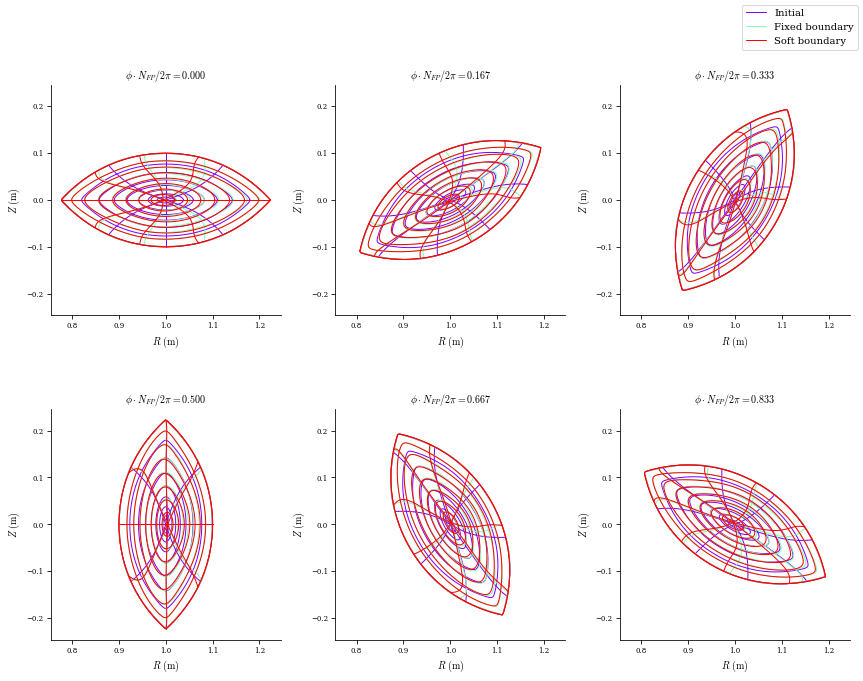

In [11]:
plot_comparison(eqs=[eq, eq1, eq2], labels=["Initial", "Fixed boundary", "Soft boundary"]);

We compute the normalized force balance error of both solutions. The volume averages are on DESC's default quadrature grid, which includes the neighbourhood of the corners, where most of the remaining error is. Note that the soft boundary gives a smaller, albeit minimally, force error.

In [12]:
for name, eq_i in (("fixed boundary", eq1), ("distance penalty", eq2)):
    f = eq_i.compute("<|F|>_vol")["<|F|>_vol"] / eq_i.compute("<|grad(|B|^2)|/2mu0>_vol")["<|grad(|B|^2)|/2mu0>_vol"]
    print(f"Force error with a {name}: {f:.4e}")

Force error with a fixed boundary: 5.6598e-02
Force error with a distance penalty: 5.2658e-02


Last, we plot $|B|$ in four cross-sections of a half field period, which by stellarator symmetry show every shape of the lemon: the fixed-boundary solution in the top row and the soft-boundary solution in the bottom row. DESC's `plot_section` evaluates on $\rho = 1$, where the tied $\lambda$ is singular at the corners, so we compute $|B|$ ourselves on the rings of the 2D notebook: two rings near the axis, 30 rings in $[0.03, 0.9]$ and 24 rings packed towards the boundary, up to $\rho = 1 - 3\times10^{-4}$, with 600 values of $\theta$ offset by half a spacing from the corners. The white lines are flux surfaces.

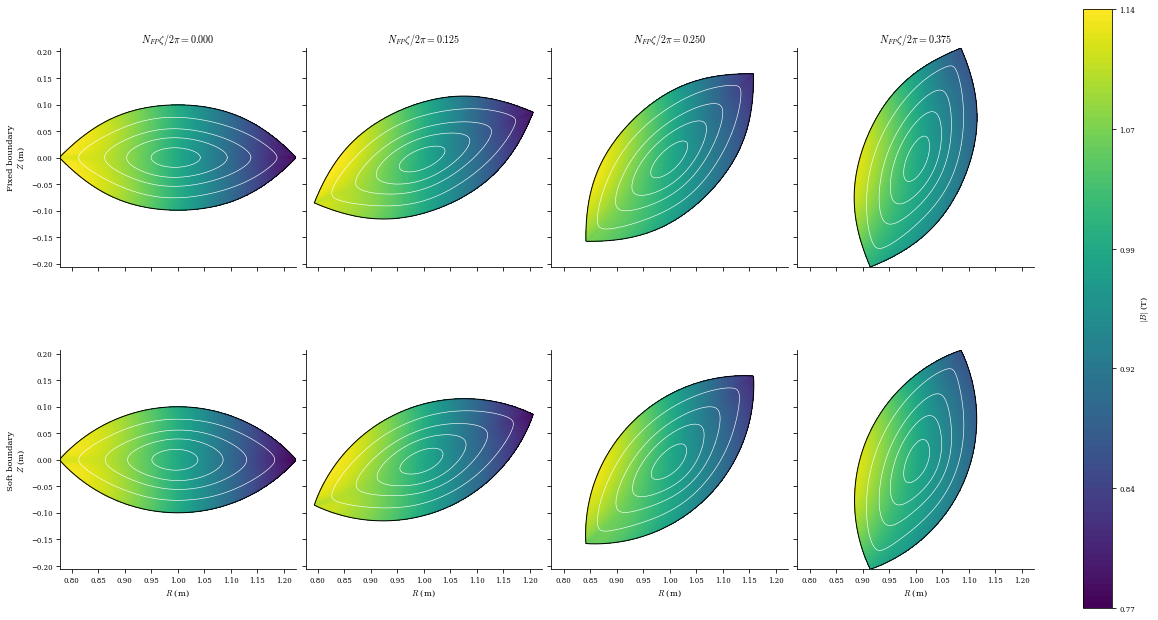

In [13]:
from desc.grid import Grid

rows = (("Fixed boundary", eq1), ("Soft boundary", eq2))
rho_g = np.concatenate([[1e-3, 1e-2], np.linspace(0.03, 0.9, 30), 1 - np.geomspace(0.1, 3e-4, 24)])
n_theta = 600
theta_g = np.linspace(0, 2 * np.pi, n_theta, endpoint=False) + np.pi / n_theta
planes = np.array([0, 1 / 8, 1 / 4, 3 / 8]) * 2 * np.pi / eq.NFP

## all four planes in one grid, so that the computation is compiled once
nodes = np.column_stack([
    np.tile(np.repeat(rho_g, n_theta), planes.size),
    np.tile(theta_g, rho_g.size * planes.size),
    np.repeat(planes, rho_g.size * n_theta),
])
data = [eq_i.compute(["R", "Z", "|B|"], grid=Grid(nodes, sort=False)) for _, eq_i in rows]
shape = (planes.size, rho_g.size, n_theta)
R, Z, B = (np.stack([np.asarray(d[k]).reshape(shape) for d in data]) for k in ("R", "Z", "|B|"))
R, Z, B = (np.concatenate([v, v[..., :1]], axis=-1) for v in (R, Z, B))  # closed in theta

fig, axs = plt.subplots(len(rows), planes.size, figsize=(16, 8.5), sharex=True, sharey=True, constrained_layout=True)
levels = np.linspace(B.min(), B.max(), 101)
for j, (name, _) in enumerate(rows):
    for k, ax in enumerate(axs[j]):
        cs = ax.contourf(R[j, k], Z[j, k], B[j, k], levels=levels, cmap="viridis")
        for i in np.searchsorted(rho_g, [0.2, 0.4, 0.6, 0.8]):
            ax.plot(R[j, k, i], Z[j, k, i], "w-", lw=0.6)
        ax.plot(R[j, k, -1], Z[j, k, -1], "k-", lw=1)
        ax.set_aspect("equal")
    axs[j, 0].set_ylabel(f"{name}\n$Z$ (m)")
for k, ax in enumerate(axs[0]):
    ax.set_title(f"$N_{{FP}}\\zeta/2\\pi = {planes[k] * eq.NFP / (2 * np.pi):.3f}$")
for ax in axs[-1]:
    ax.set_xlabel("$R$ (m)")
fig.colorbar(cs, ax=axs, label="$|B|$ (T)", ticks=np.linspace(levels[0], levels[-1], 6), format="%.2f");